# 데이터 전처리

<table align="left">
  <td>
    <a target="_blank" href="https://colab.research.google.com/github/rickiepark/hg-mldl/blob/master/2-2.ipynb"><img src="https://www.tensorflow.org/images/colab_logo_32px.png" />구글 코랩에서 실행하기</a>
  </td>
</table>

## 넘파이로 데이터 준비하기

In [211]:
beak_length = [8.2, 8.5, 8.7, 9.0, 9.1, 9.3, 9.5, 9.7, 9.8, 10.0, 8.8, 9.2, 9.6, 10.2, 8.6, 9.4, 10.1, 8.9, 9.9, 10.3, 8.4, 9.0, 9.7, 10.0, 8.7, 9.5, 10.4, 9.3, 8.9, 9.8, 10.1, 9.2, 8.5, 9.6, 10.2, 12.5, 13.0, 13.4, 13.8, 14.0, 14.3, 14.5, 14.8, 15.0, 15.3, 12.8, 13.6, 14.2, 15.5]
beak_height = [ 5.8, 6.1, 5.9, 6.3, 6.0, 6.5, 6.2, 6.7, 6.4, 6.8, 6.1, 6.4, 6.0, 6.6, 5.7, 6.3, 6.9, 6.2, 6.5, 6.7, 5.9, 6.1, 6.3, 6.4, 6.0, 6.6, 6.8, 6.2, 5.8, 6.7, 6.5, 6.0, 5.6, 6.1, 6.9, 3.2, 3.0, 3.3, 2.9, 3.1, 2.8, 3.2, 2.7, 3.0, 2.9, 3.1, 2.8, 3.0, 2.7]

In [212]:
import numpy as np

In [213]:
np.column_stack(([1,2,3], [4,5,6]))

array([[1, 4],
       [2, 5],
       [3, 6]])

In [214]:
bird_data = np.column_stack((beak_length, beak_height))

In [215]:
print(bird_data[:5])

[[8.2 5.8]
 [8.5 6.1]
 [8.7 5.9]
 [9.  6.3]
 [9.1 6. ]]


In [216]:
print(np.ones(5))

[1. 1. 1. 1. 1.]


In [217]:
bird_target = np.concatenate((np.ones(35), np.zeros(14)))

In [218]:
print(bird_target)

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0.]


## 사이킷런으로 훈련 세트와 테스트 세트 나누기

In [219]:
from sklearn.model_selection import train_test_split

In [220]:
train_input, test_input, train_target, test_target = train_test_split(
    bird_data, bird_target, random_state=42)

In [221]:
print(train_input.shape, test_input.shape)

(36, 2) (13, 2)


In [222]:
print(train_target.shape, test_target.shape)

(36,) (13,)


In [223]:
print(test_target)

[1. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [224]:
train_input, test_input, train_target, test_target = train_test_split(
    bird_data, bird_target, stratify=bird_target, random_state=42)

In [225]:
print(test_target)

[0. 0. 1. 0. 1. 0. 1. 1. 1. 1. 1. 1. 1.]


## 수상한 핀치새 한마리

In [226]:
from sklearn.neighbors import KNeighborsClassifier

kn = KNeighborsClassifier()
kn.fit(train_input, train_target)
kn.score(test_input, test_target)

1.0

In [227]:
print(kn.predict([[11.5, 4.0]]))

[0.]


In [228]:
import matplotlib.pyplot as plt

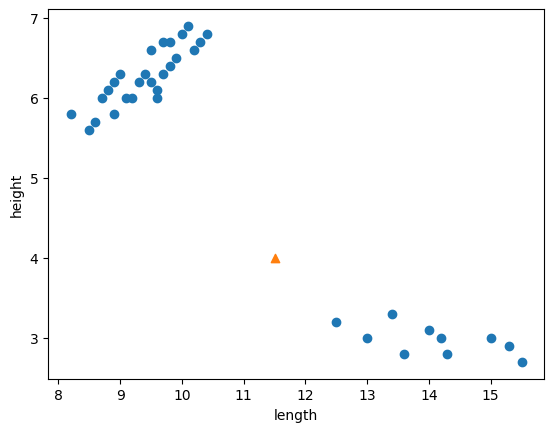

In [229]:
plt.scatter(train_input[:,0], train_input[:,1])
plt.scatter(11.5, 4.0, marker='^')
plt.xlabel('length')
plt.ylabel('height')
plt.show()

In [230]:
distances, indexes = kn.kneighbors([[11.5, 4.0]])

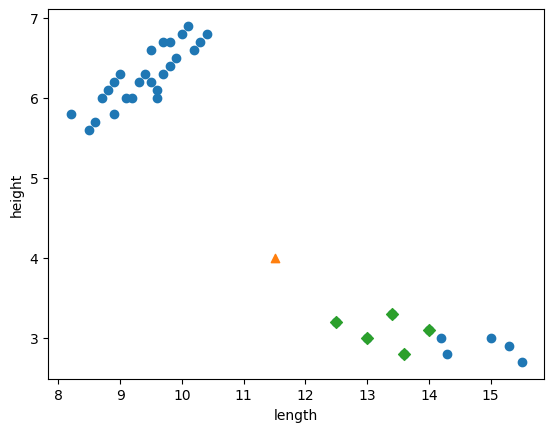

In [231]:
plt.scatter(train_input[:,0], train_input[:,1])
plt.scatter(11.5, 4.0, marker='^')
plt.scatter(train_input[indexes,0], train_input[indexes,1], marker='D')
plt.xlabel('length')
plt.ylabel('height')
plt.show()

In [232]:
print(train_input[indexes])

[[[12.5  3.2]
  [13.   3. ]
  [13.4  3.3]
  [13.6  2.8]
  [14.   3.1]]]


In [233]:
print(train_target[indexes])

[[0. 0. 0. 0. 0.]]


In [234]:
print(distances)

[[1.28062485 1.80277564 2.02484567 2.41867732 2.65706605]]


## 기준을 맞춰라

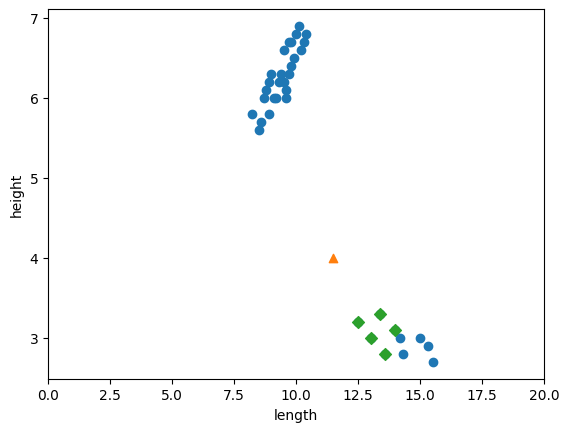

In [235]:
plt.scatter(train_input[:,0], train_input[:,1])
plt.scatter(11.5, 4.0, marker='^')
plt.scatter(train_input[indexes,0], train_input[indexes,1], marker='D')
plt.xlim((0, 20))
plt.xlabel('length')
plt.ylabel('height')
plt.show()

In [236]:
mean = np.mean(train_input, axis=0)
std = np.std(train_input, axis=0)

In [237]:
print(mean, std)

[10.70833333  5.36388889] [2.20395793 1.51275187]


In [238]:
train_scaled = (train_input - mean) / std

## 전처리 데이터로 모델 훈련하기

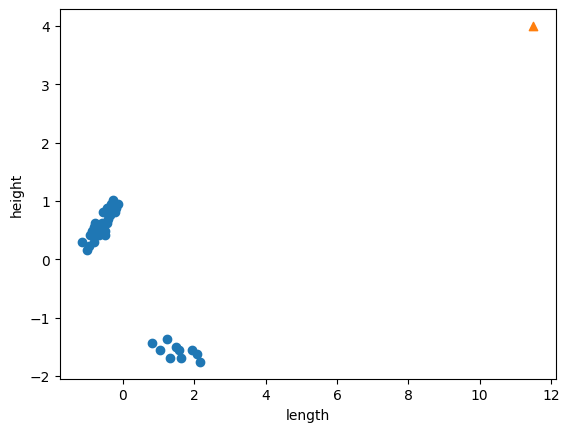

In [239]:
plt.scatter(train_scaled[:,0], train_scaled[:,1])
plt.scatter(11.5, 4.0, marker='^')
plt.xlabel('length')
plt.ylabel('height')
plt.show()

In [240]:
new = ([11.5, 4.0] - mean) / std

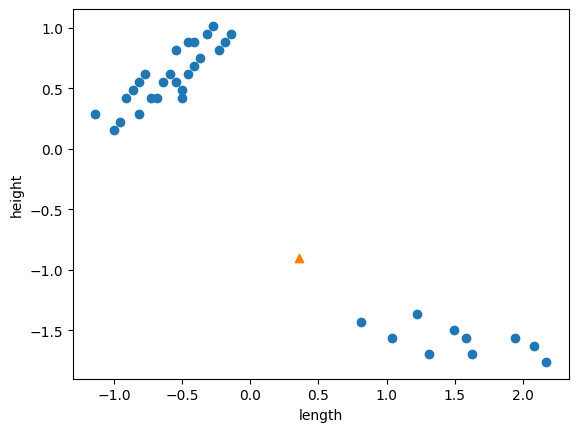

In [241]:
plt.scatter(train_scaled[:,0], train_scaled[:,1])
plt.scatter(new[0], new[1], marker='^')
plt.xlabel('length')
plt.ylabel('height')
plt.show()

In [242]:
kn.fit(train_scaled, train_target)

KNeighborsClassifier()

In [243]:
test_scaled = (test_input - mean) / std

In [244]:
kn.score(test_scaled, test_target)

1.0

In [245]:
print(kn.predict([new]))

[0.]


In [246]:
distances, indexes = kn.kneighbors([new])

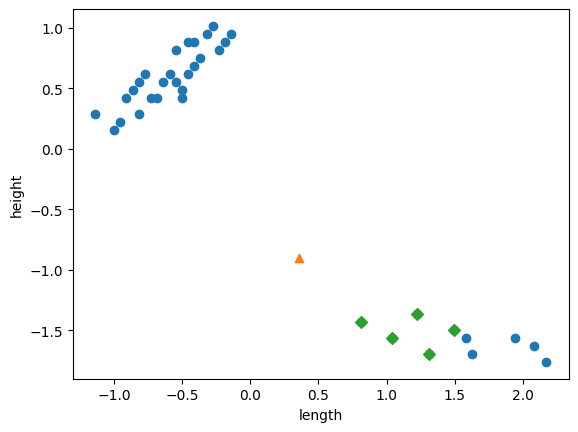

In [247]:
plt.scatter(train_scaled[:,0], train_scaled[:,1])
plt.scatter(new[0], new[1], marker='^')
plt.scatter(train_scaled[indexes,0], train_scaled[indexes,1], marker='D')
plt.xlabel('length')
plt.ylabel('height')
plt.show()